# Analisis Sentimen Pemain *Assassin's Creed Shadows*

**Pertanyaan**: bagaimana sentimen pemain terhadap *Assassin's Creed Shadows* di Steam, Reddit, dan YouTube,
dan topik apa yang paling terkait dengan sentimen positif maupun negatif?

**Pendekatan**
1. Satu metode untuk semua platform: cleaning → pelabelan lexicon (seed word + negasi) → PMI.
2. Lexicon **divalidasi** dengan label asli Steam (*Recommended / Not Recommended*).
3. PMI (*Pointwise Mutual Information*) mengukur seberapa kuat sebuah kata terkait dengan komentar positif vs negatif.

Semua logika ada di paket `src/acs_sentiment/` (dites dengan `pytest`). Notebook ini menjalankan dan menjelaskan hasilnya.

In [1]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

assert os.environ.get("JAVA_HOME"), "Set JAVA_HOME ke instalasi Java 8/11/17 sebelum menjalankan notebook"

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import functions as F

from acs_sentiment import config, pipeline, text
from acs_sentiment.pmi import top_topics

pd.set_option("display.max_colwidth", 120)
COLORS = {"positive": "#2a78d6", "neutral": "#a8a69f", "negative": "#e34948"}
spark = pipeline.get_spark("acs-sentiment-notebook")
spark.version

'3.5.9'

## 1. Data

Data mentah hasil scraping ada di `data/raw/`. Semua platform dibaca dengan Spark ke satu DataFrame
dokumen (satu baris = satu ulasan/komentar), dibersihkan, dan dilabeli.

In [2]:
docs = pipeline.load_documents(spark)
docs.groupBy("source").agg(
    F.count("*").alias("dokumen"),
    F.sum(F.col("is_english").cast("int")).alias("bahasa_inggris"),
    F.min("date").alias("dari"),
    F.max("date").alias("sampai"),
).orderBy("source").show()

+-------+-------+--------------+----------+----------+
| source|dokumen|bahasa_inggris|      dari|    sampai|
+-------+-------+--------------+----------+----------+
| reddit|    591|           591|2024-12-11|2025-12-01|
|  steam|  11988|         11925|2025-03-20|2025-11-24|
|youtube|   1147|          1146|      NULL|      NULL|
+-------+-------+--------------+----------+----------+



Ulasan Steam diambil dengan filter `language=english`, tetapi masih ada ulasan berbahasa lain
(Mandarin, Thai, Jerman, Portugis, ...). Ulasan seperti ini dibuang dengan heuristik sederhana
(`text.looks_english`). YouTube tidak punya tanggal absolut (hanya "1 bulan yang lalu").

In [3]:
(docs.filter(~F.col("is_english"))
     .select("source", F.substring("text", 1, 90).alias("contoh_non_inggris"))
     .show(6, truncate=False))

+------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|source|contoh_non_inggris                                                                                                                                                 |
+------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|steam |ก็ถ้าเล่นภาค วาฮัลลา มาก่อนภาคนี้ไม่ได้ต่างจากเดิมมากนัก ถ้าเล่นภาคนั้นแล้วหลับ ภาคนี้ก็น่                                                                         |
|steam |Самая отвратительная игра, которую я только запускал. Никогда, НИКОГДА, я больше не нажму                                                                          |
|steam |[h1]分數：8 / 10，傳奇的戰國日本，風雲地，英雄地。絕美的大和風光，如詩更如畫。[/h1]  《刺客教條：影》終於將系列的舞臺搬到萬衆期待的日本戰國時代了，在經歷《維京紀元|
|steam |Итого, за последние 10 лет 

## 2. Pelabelan sentimen dengan lexicon

Setiap komentar diberi skor = jumlah seed word positif − seed word negatif. Jika seed word didahului
kata negasi (maks. 3 kata sebelumnya), polaritasnya dibalik. Skor > 0 → positif, < 0 → negatif,
0 → netral (tidak dipakai untuk PMI).

In [4]:
contoh = [
    "Absolutely stunning world, I really enjoyed the stealth",
    "Not good. The story is boring and it keeps crashing",
    "I don't recommend it at full price",
    "Never boring, worth every penny",
    "Finished the main story yesterday",
]
pd.DataFrame({
    "komentar": contoh,
    "skor": [text.lexicon_score(text.tokenize(c)) for c in contoh],
    "label": [text.label_from_score(text.lexicon_score(text.tokenize(c))) for c in contoh],
})

,komentar,skor,label
0,"Absolutely stunning world, I really enjoyed the stealth",2,positive
1,Not good. The story is boring and it keeps crashing,-3,negative
2,I don't recommend it at full price,-1,negative
3,"Never boring, worth every penny",0,neutral
4,Finished the main story yesterday,0,neutral


## 3. Menjalankan pipeline

`pipeline.run` menghitung label, PMI per platform, validasi, lalu menulis hasil ke `output/`
(dipakai juga oleh dashboard).

In [5]:
summary, words, evaluation = pipeline.run(spark)
summary

,source,platform,documents,dropped_non_english,positive,negative,neutral,positive_share,gold_positive_share,date_min,date_max
0,steam,Steam,11925,63,7225,1367,3333,0.8409,0.7892,2025-03-20,2025-11-24
1,reddit,Reddit,591,0,336,82,173,0.8038,NaN,2024-12-11,2025-12-01
2,youtube,YouTube,1146,1,290,135,721,0.6824,NaN,NaN,NaN


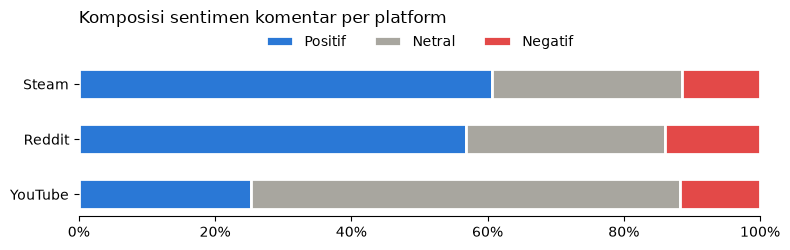

In [6]:
plot = summary.set_index("platform")[["positive", "neutral", "negative"]]
share = plot.div(plot.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(8, 2.6))
left = pd.Series(0.0, index=share.index)
for label in ["positive", "neutral", "negative"]:
    ax.barh(share.index, share[label], left=left, color=COLORS[label], height=0.55,
            edgecolor="white", linewidth=2, label={"positive": "Positif", "neutral": "Netral", "negative": "Negatif"}[label])
    left += share[label]
ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlim(0, 1)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
ax.set_title("Komposisi sentimen komentar per platform", loc="left", pad=28)
plt.tight_layout()
plt.show()

## 4. Validasi lexicon terhadap label asli Steam

Steam adalah satu-satunya sumber yang punya label sentimen asli dari penulisnya (rekomendasi).
Kita bandingkan label lexicon dengan label itu. Komentar yang dilabeli netral oleh lexicon
tidak dihitung ke akurasi, tetapi dilaporkan sebagai *coverage*.

In [7]:
steam_eval = evaluation["steam_recommendation"]
print(f"Akurasi            : {steam_eval['accuracy']:.1%}")
print(f"Macro-F1           : {steam_eval['macro_f1']:.3f}")
print(f"Baseline mayoritas : {steam_eval['majority_baseline_accuracy']:.1%}")
print(f"Coverage           : {steam_eval['coverage']:.1%} dari {steam_eval['n_total']:,} ulasan")
pd.DataFrame(steam_eval["per_class"]).T

Akurasi            : 90.6%
Macro-F1           : 0.835
Baseline mayoritas : 81.3%
Coverage           : 72.0% dari 11,925 ulasan


,precision,recall,f1,support
positive,0.9276,0.9589,0.9430,6989.0
negative,0.7901,0.6737,0.7273,1603.0


In [8]:
pd.DataFrame(steam_eval["confusion_matrix"]).T.rename_axis(index="asli \\ lexicon")

,positive,negative
asli \ lexicon,,
positive,6702,287
negative,523,1080


**Interpretasi**: akurasi lexicon (≈91%) di atas baseline yang selalu menebak kelas mayoritas (≈81%),
dengan macro-F1 ≈0,84. Kelas negatif lebih sulit
(recall lebih rendah). Ulasan negatif sering memakai sarkasme atau mengeluhkan hal spesifik
tanpa kata sentimen eksplisit. Karena itu angka porsi negatif di Reddit/YouTube kemungkinan
sedikit *underestimate*.

Untuk Reddit & YouTube belum ada label asli. File `data/annotation/sample_for_labeling.csv` berisi
200 komentar acak yang bisa dilabeli manual (kolom `gold_label`). Pipeline otomatis memakainya untuk
validasi tambahan bila sudah diisi.

## 5. Topik yang terkait dengan sentimen (PMI)

$$\text{PMI}(w, \text{pos}) = \log_2 \frac{P(w, \text{pos})}{P(w)\,P(\text{pos})}, \qquad
\text{skor}(w) = \text{PMI}(w, \text{pos}) - \text{PMI}(w, \text{neg})$$

Skor > 0: kata lebih sering muncul di komentar positif dari yang diharapkan. Seed word lexicon
dikeluarkan dari ranking karena skornya pasti tinggi (sirkular), dan kata yang muncul kurang dari
10 kali diabaikan karena skornya tidak stabil.

In [9]:
rows = []
for source in config.SOURCES:
    w = words[words["source"] == source.name]
    pos = top_topics(w, 10, polarity="positive")["word"].tolist()
    neg = top_topics(w, 10, polarity="negative")["word"].tolist()
    rows.append({"platform": source.label, "topik positif": ", ".join(pos), "topik negatif": ", ".join(neg)})
pd.DataFrame(rows).set_index("platform")

,topik positif,topik negatif
platform,,
Steam,"customize, valhallas, lovely, affect, burn, detailed, prefer, goty, flawless, refreshing","reddit, freeze, ubishit, customers, pos, deleted, directx, uninstalled, verify, request"
Reddit,"difficulty, resident, small, engaging, kassandra, march, recent, writing, read, cover","asian, fixed, patch, issue, lock, sell, yamashiro, mod, update, legendary"
YouTube,"old, fan, experience, naoe, shadows, jake, always, stealth, world, another","buy, level, japanese, wrong, okay, series, main, life, absolutely, previous"


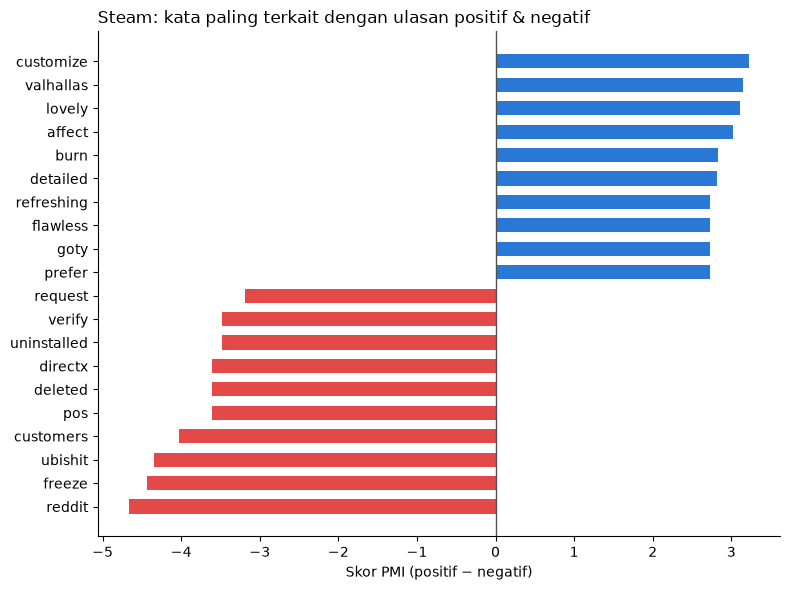

In [10]:
steam_words = words[words["source"] == "steam"]
top = pd.concat([
    top_topics(steam_words, 10, polarity="positive"),
    top_topics(steam_words, 10, polarity="negative"),
]).sort_values("sentiment_score")

fig, ax = plt.subplots(figsize=(8, 6))
colors = [COLORS["positive"] if s > 0 else COLORS["negative"] for s in top["sentiment_score"]]
ax.barh(top["word"], top["sentiment_score"], color=colors, height=0.6)
ax.axvline(0, color="#52514e", linewidth=1)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("Skor PMI (positif − negatif)")
ax.set_title("Steam: kata paling terkait dengan ulasan positif & negatif", loc="left")
plt.tight_layout()
plt.show()

## 6. Kesimpulan

- Sentimen secara umum **positif** di ketiga platform, dengan Reddit dan Steam lebih positif daripada
  komentar YouTube. Porsi *Recommended* asli Steam (~79%) konsisten dengan hasil lexicon.
- Topik **positif** di Steam terkait kualitas dan detail game (*detailed, flawless, refreshing, goty,
  customize*) serta perbandingan dengan seri sebelumnya (*valhallas*).
- Topik **negatif** di Steam didominasi **masalah teknis** (*freeze, directx, deleted, verify,
  uninstalled*) dan kekecewaan terhadap Ubisoft (*ubishit, customers*), bukan gameplay inti.

## 7. Keterbatasan

- Lexicon tidak menangkap sarkasme. Recall kelas negatif ~67% pada data Steam.
- Data YouTube berasal dari satu video dan Reddit hanya ~600 komentar, sehingga topik di dua platform
  ini lebih bising.
- Perbandingan antar platform dipengaruhi demografi pengguna yang berbeda.

In [11]:
spark.stop()